In [2]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount("/content/drive") # connect Google Colab to a Drive .csv file

# importing the necessary libraries and modules for the random forest model
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# built-in modules
import os
import warnings
import time
warnings.filterwarnings("ignore")

# download dataset via kagglehub
path = kagglehub.dataset_download("shadmanrohan/collisionavoidancechallenge")

print("Path to dataset files:", path)

import sys
print(sys.version)

Mounted at /content/drive


100%|██████████| 107M/107M [00:00<00:00, 169MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/shadmanrohan/collisionavoidancechallenge/versions/1
3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


In [3]:
os.chdir(path)
os.listdir(path)
df = pd.read_csv('train_data.csv')

In [4]:
SAVE_PATH = "/content/drive/MyDrive/2026_10_25_1.csv" # saving the path of the CSV file

In [5]:
# setting the y variable to the risk feature and
# categorizing the y variable into multiple categories
y = df["risk"].values.astype(float)
yCategories = np.empty_like(y, dtype=int)
yCategories[y < -16] = 1                     # low-risk
yCategories[(y >= -16) & (y < -9)] = 2       # medium-risk
yCategories[y >= -9] = 3                     # high-risk

In [6]:
# setting a new dataframe to read the CSV file
modelOption = "multi" # can switch depending on what model is being run

# single-feature random forest model
if modelOption == "single":
    if os.path.exists(SAVE_PATH):
        accuracyDF = pd.read_csv(SAVE_PATH)
        finishedFeatures = set(accuracyDF["feature"].unique())
    else:
        accuracyDF = pd.DataFrame(columns=["feature", "accuracy"])
        finishedFeatures = set()
elif modelOption == "multi":
    # multi-feature random forest model
    if os.path.exists(SAVE_PATH):
        accuracyDF = pd.read_csv(SAVE_PATH)
        finishedTrials = set(accuracyDF["trial"])
        print(f"Resuming — {len(finishedTrials)} trials already done")
    else:
        accuracyDF = pd.DataFrame(columns=["trial", "accuracy"])
        finishedTrials = set()

In [ ]:
def singleFeatureModel():
    # single-feature random forest model code
  allColumns = [c for c in df.columns if c == "t_sigma_r" or c == "c_sigma_r" or c == "t_sigma_t" or c == "c_sigma_t" or \
                c == "t_sigma_n" or c=="c_sigma_n" or c=="t_sigma_rdot" or c=="c_sigma_rdot" or c=="t_sigma_tdot" or \
                c=="c_sigma_tdot" or c=="t_sigma_ndot" or c=="c_sigma_ndot" or c=="F10" or c=="F3M" or c=="SSN" or \
                c=="AP"]
  for feature in allColumns:
      if feature in finishedFeatures:
          continue  # skip already finished features
      print(f"Started: {feature}")
      X = df[feature].values.reshape(-1, 1)
      accuracies = []
      for i in range(10):
          startTime = time.time()
          X_train, X_test, y_train, y_test = train_test_split(X, yCategories, test_size=0.2, random_state=i)
          model = RandomForestClassifier(n_estimators=25,random_state=i,max_depth=75)
          # fitting, predicting, and calculating accuracy scores based on X_train and Y_train
          model.fit(X_train, y_train)
          y_pred = model.predict(X_test)
          acc = accuracy_score(y_test, y_pred)
          accuracies.append(acc)
      featureDF = pd.DataFrame({
          "feature": [feature] * 10,
          "accuracy": accuracies
      })
      accuracyDF = pd.concat([accuracyDF, featureDF], ignore_index=True)
      accuracyDF.to_csv(SAVE_PATH, index=False)
      endTime = time.time()
      print(f"Completed: {feature}")
      print(f"Elapsed: {endTime - startTime:.8f}")

In [7]:
# preliminary functions

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


def getEventSplit():
    groups = df["event_id"].to_numpy()

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.2,
        random_state=42
    )

    dev_idx, test_idx = next(
        splitter.split(df, yCategories, groups=groups)
    )

    assert set(groups[dev_idx]).isdisjoint(set(groups[test_idx]))

    return dev_idx, test_idx


def cleanFeatures(X):
    limit = np.finfo(np.float32).max

    return X.where(
        np.isfinite(X) & (X.abs() <= limit),
        np.nan
    )

In [8]:
def rankFeatures():
    dev_idx, test_idx = getEventSplit()
    groups = df["event_id"].to_numpy()

    # Separate development events for ranking
    innerSplitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.25,
        random_state=21
    )

    rankTrainRel, rankValRel = next(
        innerSplitter.split(
            df.iloc[dev_idx],
            yCategories[dev_idx],
            groups=groups[dev_idx]
        )
    )

    rankTrainIdx = dev_idx[rankTrainRel]
    rankValIdx = dev_idx[rankValRel]

    excludedFeatures = {
        "event_id",
        "risk",
        "max_risk_estimate",
        "max_risk_scaling",
        "miss_distance",
        "mahalanobis_distance",
        "c_position_covariance_det",
        "t_position_covariance_det"
    }

    candidateFeatures = [
        c for c in df.select_dtypes(include=np.number).columns
        if c not in excludedFeatures
    ]

    featureScores = []

    for feature in candidateFeatures:
        print(f"Ranking feature: {feature}", flush=True)

        X_train = cleanFeatures(
            df.iloc[rankTrainIdx][[feature]].copy()
        )

        X_val = cleanFeatures(
            df.iloc[rankValIdx][[feature]].copy()
        )

        model = RandomForestClassifier(
            n_estimators=25,
            max_depth=75,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, yCategories[rankTrainIdx])

        accuracy = accuracy_score(
            yCategories[rankValIdx],
            model.predict(X_val)
        )

        featureScores.append((feature, accuracy))

    rankingDF = pd.DataFrame(
        featureScores,
        columns=["feature", "accuracy"]
    ).sort_values(
        ["accuracy", "feature"],
        ascending=[False, True]
    ).reset_index(drop=True)

    rankingDF.insert(0, "rank", range(1, len(rankingDF) + 1))

    selectedFeatures = rankingDF.head(35)["feature"].tolist()

    # Save complete ranking and final 35 features
    rankingDF.to_csv("feature_ranking.csv", index=False)

    pd.Series(selectedFeatures).to_json(
        "selected_features.json",
        orient="values",
        indent=2
    )

    print("\nTop 35 features:")
    print(rankingDF.head(35).to_string(index=False))

    print("\nNumber selected:", len(selectedFeatures))

    return selectedFeatures


In [31]:
def multiFeatureModel2():
    dev_idx, test_idx = getEventSplit()

    # load the same 35 features every time
    selectedFeatures = pd.read_json(
        "selected_features_50.json",
        typ="series"
    ).tolist()

    assert len(selectedFeatures) == 50
    assert len(set(selectedFeatures)) == 50

    X_dev = cleanFeatures(
        df.iloc[dev_idx][selectedFeatures].copy()
    )

    X_test = cleanFeatures(
        df.iloc[test_idx][selectedFeatures].copy()
    )

    y_dev = yCategories[dev_idx]
    y_test = yCategories[test_idx]

    # model = RandomForestClassifier(
    #     n_estimators=12,
    #     random_state=42,
    #     n_jobs=-1
    # )
    model = RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )

    print("Starting model training...", flush=True)

    model.fit(X_dev, y_dev)
    y_pred = model.predict(X_test)

    print("\nSelected features:")
    print(selectedFeatures)
    print("\nTraining Accuracy:",
          accuracy_score(y_dev, model.predict(X_dev)))
    print("Testing Accuracy:",
          accuracy_score(y_test, y_pred))
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        target_names=["Low", "Medium", "High"],
        zero_division=0
    ))

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[1, 2, 3]
    )

    print("\nConfusion Matrix:")
    print(cm)

    high_total = cm[2, :].sum()
    high_missed = cm[2, 0] + cm[2, 1]

    if high_total > 0:
        print(
            "\nHigh-risk false-negative rate:",
            high_missed / high_total
        )
    else:
        print("\nNo high-risk cases in test set.")

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Low", "Medium", "High"]
    ).plot(cmap="Blues", values_format="d")

    plt.title("35-Feature Random Forest Confusion Matrix")
    plt.show()

    return model

In [ ]:
rankFeatures()

Starting model training...

Selected features:
['c_time_lastob_end', 'c_time_lastob_start', 'c_obs_used', 'c_obs_available', 'c_sigma_t', 'SSN', 't_actual_od_span', 'mission_id', 't_span', 'c_residuals_accepted', 'c_sigma_rdot', 'c_span', 'F10', 'AP', 't_time_lastob_end', 't_time_lastob_start', 'F3M', 't_weighted_rms', 't_obs_used', 't_residuals_accepted', 't_recommended_od_span', 't_obs_available', 'c_rcs_estimate', 't_rcs_estimate', 'c_actual_od_span', 'c_cr_area_over_mass', 'c_recommended_od_span', 'c_cd_area_over_mass', 'c_weighted_rms', 'c_sedr', 't_cr_area_over_mass', 'c_crdot_t', 'time_to_tca', 't_sedr', 't_cd_area_over_mass', 'c_sigma_r', 't_sigma_rdot', 'relative_velocity_r', 't_sigma_t', 't_ctdot_r', 'c_sigma_tdot', 't_crdot_t', 'c_ctdot_r', 'c_sigma_ndot', 't_sigma_tdot', 'c_sigma_n', 't_sigma_r', 'relative_position_r', 't_ctdot_n', 't_crdot_r']

Training Accuracy: 0.9766761615975987
Testing Accuracy: 0.7345652038204632

Classification Report:
              precision    reca

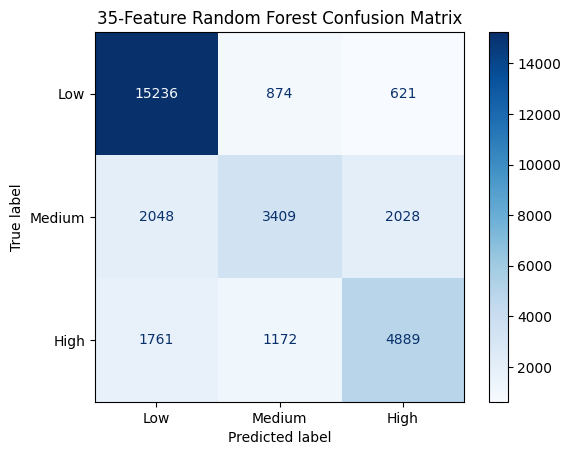

RandomForestClassifier(max_depth=20, min_samples_leaf=2, n_jobs=-1,
                       random_state=42)

In [32]:
multiFeatureModel2()

In [ ]:
from sklearn.model_selection import GroupKFold, RandomizedSearchCV

dev_idx, test_idx = getEventSplit()

selectedFeatures = pd.read_json(
    "selected_features.json",
    typ="series"
).tolist()

X_dev = cleanFeatures(
    df.iloc[dev_idx][selectedFeatures].copy()
)

y_dev = yCategories[dev_idx]
groups_dev = df.iloc[dev_idx]["event_id"].to_numpy()

param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [10, 20, 30],
    "min_samples_leaf": [2, 5, 10],
    "max_features": ["sqrt", 0.5]
}

search = RandomizedSearchCV(
    RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=param_grid,
    n_iter=10,
    scoring="f1_macro",
    cv=GroupKFold(n_splits=3),
    random_state=42,
    n_jobs=1,
    verbose=1
)

search.fit(X_dev, y_dev, groups=groups_dev)

print("Best parameters:", search.best_params_)
print("Best CV macro F1:", search.best_score_)


In [30]:
rankingDF = pd.read_csv("feature_ranking.csv")

selectedFeatures = rankingDF.head(50)["feature"].tolist()

pd.Series(selectedFeatures).to_json(
    "selected_features.json",
    orient="values",
    indent=2
)

print(selectedFeatures)

pd.Series(selectedFeatures).to_json(
    "selected_features_50.json",
    orient="values",
    indent=2
)

['c_time_lastob_end', 'c_time_lastob_start', 'c_obs_used', 'c_obs_available', 'c_sigma_t', 'SSN', 't_actual_od_span', 'mission_id', 't_span', 'c_residuals_accepted', 'c_sigma_rdot', 'c_span', 'F10', 'AP', 't_time_lastob_end', 't_time_lastob_start', 'F3M', 't_weighted_rms', 't_obs_used', 't_residuals_accepted', 't_recommended_od_span', 't_obs_available', 'c_rcs_estimate', 't_rcs_estimate', 'c_actual_od_span', 'c_cr_area_over_mass', 'c_recommended_od_span', 'c_cd_area_over_mass', 'c_weighted_rms', 'c_sedr', 't_cr_area_over_mass', 'c_crdot_t', 'time_to_tca', 't_sedr', 't_cd_area_over_mass', 'c_sigma_r', 't_sigma_rdot', 'relative_velocity_r', 't_sigma_t', 't_ctdot_r', 'c_sigma_tdot', 't_crdot_t', 'c_ctdot_r', 'c_sigma_ndot', 't_sigma_tdot', 'c_sigma_n', 't_sigma_r', 'relative_position_r', 't_ctdot_n', 't_crdot_r']
